# Project 1: Customer Churn Predictor (NetPulse Broadband)

**Folder:** `27_pandas/project/` | **Level:** Intermediate | **Time:** 2 to 3 hours | **Libraries:** NumPy, pandas, Matplotlib (no scikit-learn needed)

## The business problem

NetPulse is a broadband company with about 8,000 customers in six Indian cities. About **4 out of every 100 customers leave every month** (churn). Winning a new customer costs far more than keeping one, so the retention team wants to **call the customers who are about to leave** and offer them a discount.

But the team can only call a limited number of people, and every call costs money. So the real question is:

> **Which customers should we call this month, so that the retention budget earns the most money?**

## What you will build

1. Read **three messy raw files** (customers, monthly usage, support tickets) and clean them
2. Turn thousands of rows of history into **one row per customer** (feature engineering)
3. Predict **"will this customer churn in the next 30 days?"** with a **logistic regression written from scratch in NumPy**
4. Evaluate with the right metrics (ROC AUC, precision-recall, lift) and a **time-based split**
5. Convert the predictions into a **business decision** (who to call) and measure the profit

## Skills map (this is your revision sheet)

| Skill | Where it is used here | Theory notebook |
|---|---|---|
| Reading files, `read_csv` options | loading the 3 raw files | 03 |
| `info`, `describe`, `value_counts`, `duplicated` | understanding the raw data | 04 |
| Missing values, fake missing markers | invalid ages and speeds | 07 |
| Text/number cleaning, dates, duplicates, outliers | `Rs. 719`, mixed date formats, `"2 year"` | 08 |
| `merge`, `join` with `validate` | combining customers, usage, tickets | 11 |
| `groupby` + named aggregation, `pivot` | usage and ticket features | 10, 12 |
| Dates, `Period`, time windows | snapshots, "last 3 months", "last 90 days" | 13 |
| `where`, `clip`, `cut`, `map`, `get_dummies` | feature preparation | 05, 06 |
| NumPy: vectorization, broadcasting, `@`, `argsort`, `cumsum` | logistic regression, metrics, profit curve | 26_numpy |
| Matplotlib: subplots, bars, hist, ROC, heatmap | all the charts | 15 |
| Time-safe features and train/test split, leakage | the snapshot design | 09, 13 |

## How to use this notebook for interviews

Every section ends with a **"Say it in an interview"** box: the one-minute explanation of what you did and why. The last section has resume bullets and 10 likely questions.

---
# 0. Setup

In [2]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

PROJECT = "project_1_customer_churn_predictor"
DATA = Path("data") / PROJECT           # raw and clean files
FIG = Path("figures") / PROJECT         # charts for your README
DATA.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

SEED = 7
plt.rcParams.update({
    "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "axes.titlesize": 12, "axes.titleweight": "bold",
})

def savefig(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 3.0.6 | numpy 2.5.3


---
# 1. The raw data

In a real job the files arrive from a data warehouse or a colleague. Here we **simulate** them with a seeded generator, so the notebook is 100% reproducible and runs on any laptop. The files are built to look like real company exports, **with real-world problems on purpose** (duplicates, text numbers, mixed date formats, impossible values).

> The next cell is the simulator. You do **not** need to read it to learn the project. The churn in the data is generated from *past behaviour only* (outages, support tickets, falling usage, contract type...), exactly the kind of patterns real churn has.

**If you have a real dataset** (for example a telecom churn CSV from Kaggle) you can skip the simulator and load your own files in section 1.2, then adapt the column names.

In [3]:
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -30, 30)))


def make_netpulse(seed=7, n=8000):
    """Simulate the raw files of a broadband company: customers, monthly usage and support tickets.
    Churn is simulated month by month from PAST behaviour only (outages, tickets, falling usage, contract...)."""
    rng = np.random.default_rng(seed)
    months = pd.period_range("2025-07", "2026-05", freq="M")          # 11 months, index 9 = Apr 2026, 10 = May 2026
    M = len(months)

    # ---------- customer attributes ----------
    signup = pd.Timestamp("2022-01-01") + pd.to_timedelta(rng.integers(0, 1550, n), unit="D")     # until about Mar 2026
    signup_idx = np.clip(((signup.year - 2025) * 12 + signup.month - 7).to_numpy(), -100, 100)    # month index (0 = Jul 2025)
    plan = rng.choice(["Basic", "Standard", "Premium"], n, p=[0.45, 0.40, 0.15])
    price = pd.Series(plan).map({"Basic": 499, "Standard": 799, "Premium": 1299}).to_numpy()
    speed = pd.Series(plan).map({"Basic": 100, "Standard": 300, "Premium": 1000}).to_numpy()
    contract = rng.choice(["Monthly", "Annual", "Two-year"], n, p=[0.55, 0.30, 0.15])
    autopay = rng.random(n) < np.where(contract == "Monthly", 0.35, 0.65)
    payment = np.where(autopay, rng.choice(["UPI AutoPay", "Card"], n, p=[0.7, 0.3]),
                       rng.choice(["NetBanking", "Cash/Cheque"], n, p=[0.6, 0.4]))
    city = rng.choice(["Indore", "Bhopal", "Pune", "Jaipur", "Lucknow", "Nagpur"], n, p=[0.25, 0.2, 0.2, 0.15, 0.1, 0.1])
    age = np.clip(rng.normal(38, 12, n), 18, 80).round(0)
    discount = np.where(contract == "Monthly", rng.choice([0, 0.05], n, p=[0.8, 0.2]), rng.choice([0.1, 0.15], n))
    charge = (price * (1 - discount)).round(0)

    # ---------- monthly behaviour (arrays: customers x months) ----------
    quality = rng.gamma(2.0, 0.5, n)                                         # how bad the local network is (mean 1)
    outage = rng.poisson(20 * quality[:, None], (n, M)).astype(float)
    spikes = rng.random((n, M)) < 0.05
    outage = outage + spikes * rng.integers(120, 600, (n, M))

    disengaged = rng.random(n) < 0.15
    decay_start = rng.integers(2, 8, n)
    base_gb = pd.Series(plan).map({"Basic": 250, "Standard": 450, "Premium": 800}).to_numpy() * rng.lognormal(0, 0.35, n)
    month_idx = np.arange(M)[None, :]
    decay = np.where(disengaged[:, None] & (month_idx >= decay_start[:, None]), 0.8 ** (month_idx - decay_start[:, None] + 1), 1.0)
    data_gb = (base_gb[:, None] * decay * rng.lognormal(0, 0.12, (n, M))).round(1)

    tick_lambda = 0.06 + 0.0035 * outage + 0.08 * disengaged[:, None]
    tick_n = rng.poisson(tick_lambda)

    # ticket level records
    cust_i, month_i = np.nonzero(tick_n)
    reps = tick_n[cust_i, month_i]
    t_cust = np.repeat(cust_i, reps)
    t_month = np.repeat(month_i, reps)
    t_cat = rng.choice(["technical", "billing", "speed", "other"], len(t_cust), p=[0.40, 0.30, 0.20, 0.10])
    t_res = np.where(t_cat == "technical", rng.gamma(2, 12, len(t_cust)), rng.gamma(2, 5, len(t_cust))).round(1)
    t_sat = np.clip(np.round(5 - t_res / 18 + rng.normal(0, 0.8, len(t_cust))), 1, 5)
    t_sat = np.where(rng.random(len(t_cust)) < 0.35, t_sat, np.nan)                    # most people never answer the survey
    t_day = rng.integers(1, 28, len(t_cust))
    tickets = pd.DataFrame({"customer_idx": t_cust, "month_idx": t_month, "day": t_day, "category": t_cat,
                            "resolved_hours": t_res, "satisfaction": t_sat})

    tick_by_month = np.zeros((n, M))
    low_sat_by_month = np.zeros((n, M))
    np.add.at(tick_by_month, (tickets["customer_idx"], tickets["month_idx"]), 1)
    low = tickets[tickets["satisfaction"] <= 2]
    np.add.at(low_sat_by_month, (low["customer_idx"], low["month_idx"]), 1)

    # ---------- churn simulated month by month, using only PAST months ----------
    churn_month = np.full(n, -1)
    tenure_at = lambda m: (m - signup_idx)
    for m in range(3, M):
        alive = (churn_month == -1) & (signup_idx <= m - 1)
        out3 = outage[:, max(m - 3, 0):m].mean(axis=1)
        tick2 = tick_by_month[:, max(m - 2, 0):m].sum(axis=1)
        low2 = low_sat_by_month[:, max(m - 2, 0):m].sum(axis=1) > 0
        drop = data_gb[:, m - 1] / np.maximum(data_gb[:, m - 4], 1) < 0.7
        z = (-4.4
             + 1.0 * (contract == "Monthly") - 0.7 * (contract == "Two-year")
             - 0.7 * autopay
             + 0.6 * (tenure_at(m) < 6) + 0.3 * (tenure_at(m) < 12)
             + 0.010 * out3
             + 0.30 * tick2 + 0.9 * low2
             + 1.0 * drop
             + 0.0006 * (charge - 700))
        draw = rng.random(n) < sigmoid(z)
        churn_month[alive & draw] = m

    churned = churn_month >= 0
    churn_date = pd.Series(pd.NaT, index=range(n), dtype="datetime64[us]")
    start_of_month = pd.to_datetime([months[m].start_time for m in churn_month[churned]])
    churn_date[churned] = start_of_month + pd.to_timedelta(rng.integers(0, 27, churned.sum()), unit="D")

    # ---------- raw tables, with real-world mess ----------
    cust_ids = np.array([f"C{i:05d}" for i in range(1, n + 1)])

    # usage: only months after signup and before churn month
    rows = []
    exists = (month_idx >= np.maximum(signup_idx, 0)[:, None]) & ((churn_month[:, None] == -1) | (month_idx < churn_month[:, None])) & (month_idx <= 9)
    ci, mi = np.nonzero(exists)
    speed_ratio = np.clip(0.97 - 0.0004 * outage[ci, mi] + rng.normal(0, 0.03, len(ci)), 0.3, 1.0)
    usage = pd.DataFrame({
        "customer_id": cust_ids[ci],
        "month": months[mi].astype(str),
        "data_gb": data_gb[ci, mi],
        "avg_speed_mbps": (speed[ci] * speed_ratio).round(1),
        "outage_minutes": outage[ci, mi],
    })
    usage.loc[rng.random(len(usage)) < 0.004, "avg_speed_mbps"] = -1                   # sensor errors
    usage = usage.sample(frac=0.98, random_state=1).sort_values(["customer_id", "month"]).reset_index(drop=True)   # 2% rows missing

    tk = tickets[(tickets["month_idx"] <= 9) & ((churn_month[tickets["customer_idx"]] == -1) | (tickets["month_idx"] < churn_month[tickets["customer_idx"]]))].copy()
    tk["customer_id"] = cust_ids[tk["customer_idx"]]
    tk["created_at"] = [pd.Timestamp(months[m].start_time) + pd.Timedelta(days=int(d), hours=int(h)) for m, d, h in
                        zip(tk["month_idx"], tk["day"], rng.integers(8, 22, len(tk)))]
    tk["category"] = [c if rng.random() > 0.15 else c.upper() for c in tk["category"]]
    tk["ticket_id"] = [f"T{i:06d}" for i in range(1, len(tk) + 1)]
    tickets_raw = tk[["ticket_id", "customer_id", "created_at", "category", "resolved_hours", "satisfaction"]].reset_index(drop=True)

    # customers: messy text
    fmt = rng.random(n)
    signup_txt = np.where(fmt < 0.8, signup.strftime("%Y-%m-%d"), signup.strftime("%d/%m/%Y"))
    contract_txt = np.array([c if rng.random() > 0.2 else rng.choice([c.lower(), c.upper(), " " + c, c + " "]) for c in contract])
    contract_txt = np.where(contract_txt == "Two-year", np.where(rng.random(n) < 0.3, "2 year", "Two-year"), contract_txt)
    city_txt = np.array([c if rng.random() > 0.05 else c.lower() for c in city])
    customers = pd.DataFrame({
        "customer_id": cust_ids,
        "signup_date": signup_txt,
        "city": city_txt,
        "plan": plan,
        "contract": contract_txt,
        "payment_method": payment,
        "monthly_charge": ["Rs. {:,.0f}".format(c) if rng.random() < 0.5 else str(int(c)) for c in charge],
        "age": age,
        "churn_date": churn_date.dt.strftime("%Y-%m-%d"),
    })
    customers.loc[rng.random(n) < 0.05, "age"] = np.nan
    customers.loc[rng.random(n) < 0.004, "age"] = 0                                    # impossible values
    customers = pd.concat([customers, customers.sample(40, random_state=2)], ignore_index=True)   # duplicated rows
    return customers, usage, tickets_raw, churn_month

In [4]:
customers_raw, usage_raw, tickets_raw, _hidden_truth = make_netpulse(seed=SEED, n=8000)

# Save the 3 raw files exactly like a company export, then forget the simulator
customers_raw.to_csv(DATA / "customers_raw.csv", index=False)
usage_raw.to_csv(DATA / "usage_raw.csv", index=False)
tickets_raw.to_csv(DATA / "tickets_raw.csv", index=False)
print(sorted(p.name for p in DATA.glob("*_raw.csv")))

['customers_raw.csv', 'tickets_raw.csv', 'usage_raw.csv']


## 1.2 Load the files (the way you would at work)

`customer_id` is a **label**, not a number, so we read it as text (chapter 03).

In [5]:
customers = pd.read_csv(DATA / "customers_raw.csv", dtype={"customer_id": "str"})
usage = pd.read_csv(DATA / "usage_raw.csv", dtype={"customer_id": "str"})
tickets = pd.read_csv(DATA / "tickets_raw.csv", dtype={"customer_id": "str"}, parse_dates=["created_at"])

for name, d in [("customers", customers), ("usage", usage), ("tickets", tickets)]:
    print(f"{name:10s} rows={len(d):6d} columns={d.shape[1]}")

customers  rows=  8040 columns=9
usage      rows= 64867 columns=5
tickets    rows= 14536 columns=6


## Data dictionary

| File | Column | Meaning |
|---|---|---|
| customers | `customer_id` | unique customer |
| | `signup_date` | when the connection started (text, mixed formats) |
| | `city`, `plan` | where, and which speed plan (Basic 100 / Standard 300 / Premium 1000 Mbps) |
| | `contract` | Monthly, Annual or Two-year |
| | `payment_method` | UPI AutoPay, Card, NetBanking, Cash/Cheque |
| | `monthly_charge` | bill in rupees (text, e.g. `Rs. 719`) |
| | `age` | customer age |
| | `churn_date` | date the customer left (empty = still active) |
| usage | `customer_id`, `month` | one row per customer per month |
| | `data_gb`, `avg_speed_mbps`, `outage_minutes` | usage, measured speed, minutes without service |
| tickets | `ticket_id`, `customer_id`, `created_at` | support ticket |
| | `category`, `resolved_hours`, `satisfaction` | type, time to resolve, survey score 1 to 5 (most do not answer) |

---
# 2. Understand the data before touching it (chapter 04)

In [6]:
customers.head()

,customer_id,signup_date,city,plan,contract,payment_method,monthly_charge,age,churn_date
0,C00001,2026-01-04,Indore,Standard,TWO-YEAR,Card,Rs. 719,52.0,NaN
1,C00002,2024-08-26,Pune,Basic,Monthly,NetBanking,499,45.0,NaN
2,C00003,2024-11-26,Nagpur,Standard,Monthly,UPI AutoPay,Rs. 799,34.0,NaN
3,C00004,2025-10-22,Pune,Standard,2 year,NetBanking,679,45.0,NaN
4,C00005,2024-06-15,Pune,Basic,Annual,Card,449,38.0,NaN


In [7]:
customers.info()

<class 'pandas.DataFrame'>
RangeIndex: 8040 entries, 0 to 8039
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   customer_id     8040 non-null   str    
 1   signup_date     8040 non-null   str    
 2   city            8040 non-null   str    
 3   plan            8040 non-null   str    
 4   contract        8040 non-null   str    
 5   payment_method  8040 non-null   str    
 6   monthly_charge  8040 non-null   str    
 7   age             7616 non-null   float64
 8   churn_date      2244 non-null   str    
dtypes: float64(1), str(8)
memory usage: 980.7 KB


In [8]:
def quick_look(df, name):
    rep = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing": df.isna().sum(),
        "missing_%": (df.isna().mean() * 100).round(1),
        "unique": df.nunique(),
    })
    print(f"--- {name}: {df.shape[0]} rows, {df.duplicated().sum()} exact duplicate rows ---")
    return rep

quick_look(customers, "customers")

--- customers: 8040 rows, 40 exact duplicate rows ---


,dtype,missing,missing_%,unique
customer_id,str,0,0.0,8000
signup_date,str,0,0.0,2486
city,str,0,0.0,12
plan,str,0,0.0,3
contract,str,0,0.0,16
payment_method,str,0,0.0,4
monthly_charge,str,0,0.0,24
age,float64,424,5.3,64
churn_date,str,5796,72.1,216


In [9]:
# Look for inconsistent categories with value_counts
print(customers["contract"].value_counts(), "\n")
print(customers["city"].value_counts(), "\n")
print(customers["signup_date"].str.len().value_counts().rename("length of the date text"))

contract
Monthly      3498
Annual       1966
Two-year      661
2 year        293
MONTHLY       229
monthly       229
Monthly       223
 Monthly      205
 Annual       129
ANNUAL        122
Annual        119
annual        116
two-year       70
TWO-YEAR       60
 Two-year      60
Two-year       60
Name: count, dtype: int64 

city
Indore     1889
Bhopal     1604
Pune       1444
Jaipur     1174
Nagpur      755
Lucknow     743
pune         99
indore       97
bhopal       79
lucknow      60
nagpur       50
jaipur       46
Name: count, dtype: int64 

signup_date
10    8040
Name: length of the date text, dtype: int64


In [10]:
quick_look(usage, "usage")

--- usage: 64867 rows, 0 exact duplicate rows ---


,dtype,missing,missing_%,unique
customer_id,str,0,0.0,7998
month,str,0,0.0,10
data_gb,float64,0,0.0,11249
avg_speed_mbps,float64,0,0.0,2625
outage_minutes,float64,0,0.0,631


In [11]:
print(usage["avg_speed_mbps"].describe().round(1))
print("negative speeds:", (usage["avg_speed_mbps"] < 0).sum())

count    64867.0
mean       296.8
std        289.2
min         -1.0
25%         96.3
50%        273.8
75%        294.2
max       1000.0
Name: avg_speed_mbps, dtype: float64
negative speeds: 260


In [12]:
quick_look(tickets, "tickets")

--- tickets: 14536 rows, 0 exact duplicate rows ---


,dtype,missing,missing_%,unique
ticket_id,str,0,0.0,14536
customer_id,str,0,0.0,6121
created_at,datetime64[us],0,0.0,3692
category,str,0,0.0,8
resolved_hours,float64,0,0.0,738
satisfaction,float64,9484,65.2,5


In [13]:
print(tickets["category"].value_counts())

category
technical    4972
billing      3679
speed        2516
other        1221
TECHNICAL     852
BILLING       661
SPEED         444
OTHER         191
Name: count, dtype: int64


### Problems we found (our to-do list)

| Table | Problem | Fix |
|---|---|---|
| customers | 40 duplicated rows | `drop_duplicates(subset="customer_id")` |
| customers | `monthly_charge` is text (`Rs. 719`) | remove symbols, convert to number |
| customers | `signup_date` in two formats | two-pass parsing (ISO first, then day-first) |
| customers | `contract` has `monthly`, `ANNUAL`, ` Two-year`, `2 year` | strip, title-case, map |
| customers | city in lowercase | title-case |
| customers | impossible `age` (0), missing ages | set to NaN, fill later with the median **learned from training data only** |
| usage | negative speed (sensor error `-1`) | NaN |
| usage | some months missing | handle with `groupby` (missing months are simply not counted) |
| tickets | category in upper case sometimes | lower-case |
| tickets | satisfaction mostly empty | do not fill. "Did not answer" is normal. Use only the low scores |

**Say it in an interview:** "Before modelling I profiled each table, listed every data-quality problem, and fixed them one by one with a cleaning log, so every change is documented and repeatable."

---
# 3. Cleaning (chapters 07 and 08)

We keep a **cleaning log**: how many rows or values each step changed. In a real project this table goes into your report.

In [14]:
log = []

def note(table, step, changed):
    log.append({"table": table, "step": step, "values_changed": int(changed)})

# ---------------- customers ----------------
c = customers.copy()

# 1. duplicates
before = len(c)
c = c.drop_duplicates(subset="customer_id", keep="first")
note("customers", "drop duplicate customer rows", before - len(c))

# 2. monthly_charge: "Rs. 719" -> 719
is_text = c["monthly_charge"].str.contains("Rs", na=False)
c["monthly_charge"] = pd.to_numeric(c["monthly_charge"].str.replace(r"[^\d]", "", regex=True))
note("customers", "monthly_charge text -> number", is_text.sum())

# 3. signup_date: two passes (ISO first, then day-first), chapter 08
text = c["signup_date"].str.strip()
iso = pd.to_datetime(text, format="ISO8601", errors="coerce")
rest = pd.to_datetime(text.where(iso.isna()), format="mixed", dayfirst=True, errors="coerce")
c["signup_date"] = iso.fillna(rest)
note("customers", "signup_date parsed (non-ISO formats)", iso.isna().sum())

# 4. contract and city text
raw_contract = c["contract"].copy()
CONTRACT_MAP = {"monthly": "Monthly", "annual": "Annual", "two-year": "Two-year", "2 year": "Two-year"}
c["contract"] = c["contract"].str.strip().str.lower().map(CONTRACT_MAP)           # unknown spellings would become NaN and be caught by the asserts
note("customers", "contract spelling normalised", (raw_contract != c["contract"]).sum())
c["city"] = c["city"].str.strip().str.title()

# 5. age: impossible values -> NaN
bad_age = c["age"].notna() & ~c["age"].between(18, 90)
c.loc[bad_age, "age"] = np.nan
note("customers", "impossible age -> NaN", bad_age.sum())

# 6. churn date
c["churn_date"] = pd.to_datetime(c["churn_date"])

# ---------------- usage ----------------
u = usage.copy()
u["month"] = pd.to_datetime(u["month"] + "-01").dt.to_period("M")
bad_speed = u["avg_speed_mbps"] < 0
u.loc[bad_speed, "avg_speed_mbps"] = np.nan
note("usage", "negative speed -> NaN", bad_speed.sum())

# plan speed lets us compute "how much of the promised speed did the customer get"
plan_speed = {"Basic": 100, "Standard": 300, "Premium": 1000}
u = u.merge(c[["customer_id", "plan"]], on="customer_id", how="left", validate="many_to_one")
u["speed_ratio"] = (u["avg_speed_mbps"] / u["plan"].map(plan_speed)).clip(upper=1.0)
u = u.drop(columns="plan")

# ---------------- tickets ----------------
t = tickets.copy()
t["category"] = t["category"].str.strip().str.lower()
note("tickets", "category lower-cased", (tickets["category"] != t["category"]).sum())

pd.DataFrame(log)

,table,step,values_changed
0,customers,drop duplicate customer rows,40
1,customers,monthly_charge text -> number,3997
2,customers,signup_date parsed (non-ISO formats),1612
3,customers,contract spelling normalised,1906
4,customers,impossible age -> NaN,27
5,usage,negative speed -> NaN,260
6,tickets,category lower-cased,2148


In [15]:
# Validation: write the rules as asserts, so a broken cleaning step stops the notebook
assert c["customer_id"].is_unique
assert c["monthly_charge"].between(300, 1500).all()
assert c["signup_date"].notna().all()
assert set(c["contract"]) == {"Monthly", "Annual", "Two-year"}, set(c["contract"])
assert c["age"].dropna().between(18, 90).all()
assert (u["avg_speed_mbps"].dropna() >= 0).all()
assert u.merge(c[["customer_id"]], on="customer_id", how="left", indicator=True)["_merge"].eq("both").all()   # no orphan usage rows
print("all validation rules passed")
print(c["contract"].value_counts().to_dict())

all validation rules passed
{'Monthly': 4360, 'Annual': 2443, 'Two-year': 1197}


**Say it in an interview:** "I cleaned in a fixed order: duplicates, text, numbers, dates, categories, impossible values. I wrote the rules as `assert` statements and kept a cleaning log. Impossible values became NaN instead of guesses."

---
# 4. Define the prediction task: snapshots and labels

A churn model must answer: **"standing on a given day, who will leave in the next 30 days?"**

- A **snapshot date** is "today" in the model's world. Features may only use data **up to** the snapshot.
- The **label** is 1 if the customer churns in the **next 30 days**, otherwise 0.
- Only customers who are **still active** on the snapshot are scored (people who already left cannot "churn" again).

To learn from the past and test on the future, we use **several monthly snapshots**:

```
 Jan 31 ─ label: churn in Feb ─┐
 Feb 28 ─ label: churn in Mar ─┼── TRAIN (3 snapshots stacked)
 Mar 31 ─ label: churn in Apr ─┘
 Apr 30 ─ label: churn in May ──── TEST (the future the model never saw)
```

In [16]:
TRAIN_SNAPSHOTS = ["2026-01-31", "2026-02-28", "2026-03-31"]
TEST_SNAPSHOT = "2026-04-30"
HORIZON_DAYS = 30

def active_on(customers, snapshot):
    snap = pd.Timestamp(snapshot)
    return customers[(customers["signup_date"] <= snap) & (customers["churn_date"].isna() | (customers["churn_date"] > snap))]

def churn_label(customers, snapshot, horizon=HORIZON_DAYS):
    """1 if the customer churns in the 30 days after the snapshot."""
    snap = pd.Timestamp(snapshot)
    end = snap + pd.Timedelta(days=horizon)
    return (customers["churn_date"] > snap) & (customers["churn_date"] <= end)

rows = []
for s in TRAIN_SNAPSHOTS + [TEST_SNAPSHOT]:
    a = active_on(c, s)
    rows.append({"snapshot": s, "active_customers": len(a), "churners_next_30d": int(churn_label(a, s).sum()),
                 "churn_rate_%": round(churn_label(a, s).mean() * 100, 2)})
pd.DataFrame(rows)

,snapshot,active_customers,churners_next_30d,churn_rate_%
0,2026-01-31,6502,285,4.38
1,2026-02-28,6371,285,4.47
2,2026-03-31,6245,262,4.20
3,2026-04-30,5983,215,3.59


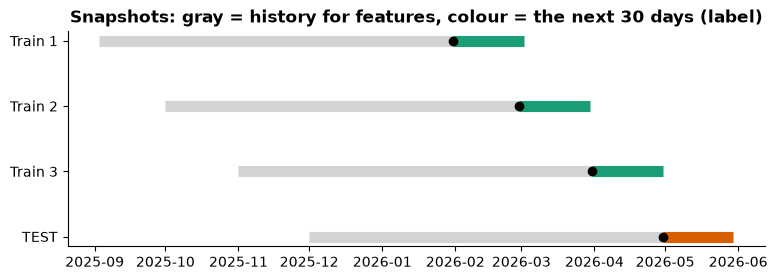

In [17]:
# A picture of the design (chart 1)
fig, ax = plt.subplots(figsize=(9, 2.8))
for i, s in enumerate(TRAIN_SNAPSHOTS + [TEST_SNAPSHOT]):
    snap = pd.Timestamp(s)
    color = "#1b9e77" if s in TRAIN_SNAPSHOTS else "#d95f02"
    ax.hlines(i, snap - pd.Timedelta(days=150), snap, color="lightgray", linewidth=8)          # history used for features
    ax.hlines(i, snap, snap + pd.Timedelta(days=30), color=color, linewidth=8)                  # label window
    ax.plot(snap, i, "o", color="black")
ax.set_yticks(range(4))
ax.set_yticklabels(["Train 1", "Train 2", "Train 3", "TEST"])
ax.set_title("Snapshots: gray = history for features, colour = the next 30 days (label)")
ax.invert_yaxis()
ax.grid(False)
plt.show()
savefig(fig, "01_snapshot_design")

---
# 5. Feature engineering: from history to one row per customer (chapters 10, 11, 12, 13)

This is the heart of the project. For a given snapshot we build, for **every active customer**:

| Feature group | Features | Why it should matter |
|---|---|---|
| **Customer** | tenure, plan, contract, autopay, payment method, monthly charge, age, city | new customers and monthly contracts leave more |
| **Usage** | average data (3 months), **change vs 3 months ago**, outage minutes, worst outage, speed ratio | falling usage means disengagement, outages cause anger |
| **Support** | tickets in the last 60 and 90 days, technical tickets, resolution time, low satisfaction, days since last ticket | unhappy customers contact support |

Everything is computed with data **up to the snapshot only**. The whole procedure is **one function**, so we can run it again for every snapshot (and later, for today's real call list).

In [18]:
def build_features(customers, usage, tickets, snapshot):
    snap = pd.Timestamp(snapshot)
    snap_m = snap.to_period("M")

    base = active_on(customers, snapshot).copy()
    base["tenure_months"] = ((snap - base["signup_date"]).dt.days / 30.44).round(1)
    base["is_new"] = (base["tenure_months"] < 6).astype(int)
    base["autopay"] = base["payment_method"].isin(["UPI AutoPay", "Card"]).astype(int)

    # ----- usage: only months up to the snapshot -----
    u = usage[usage["month"] <= snap_m]
    last3 = u[u["month"] > snap_m - 3]
    f_use = last3.groupby("customer_id").agg(
        avg_data_gb_3m=("data_gb", "mean"),
        avg_outage_3m=("outage_minutes", "mean"),
        max_outage_3m=("outage_minutes", "max"),
        avg_speed_ratio_3m=("speed_ratio", "mean"),
    )

    # data used now vs 3 months ago (pivot: customers x months)
    wide = u[u["month"].isin([snap_m, snap_m - 3])].pivot(index="customer_id", columns="month", values="data_gb")
    if snap_m in wide.columns and (snap_m - 3) in wide.columns:
        f_use["gb_now_vs_3m_ago"] = (wide[snap_m] / wide[snap_m - 3]).reindex(f_use.index)

    # ----- tickets: only tickets created up to the snapshot -----
    tk = tickets[tickets["created_at"] <= snap]
    last90 = tk[tk["created_at"] > snap - pd.Timedelta(days=90)]
    last60 = tk[tk["created_at"] > snap - pd.Timedelta(days=60)]

    f_t90 = last90.groupby("customer_id").agg(
        n_tickets_90d=("ticket_id", "count"),
        n_technical_90d=("category", lambda s: (s == "technical").sum()),
        avg_resolution_h=("resolved_hours", "mean"),
    )
    f_t60 = last60.groupby("customer_id").agg(
        n_tickets_60d=("ticket_id", "count"),
        low_sat_60d=("satisfaction", lambda s: int((s <= 2).any())),
    )
    last_ticket = tk.groupby("customer_id")["created_at"].max()
    f_last = ((snap - last_ticket).dt.days).rename("days_since_last_ticket").to_frame()

    # ----- combine everything onto the customer list (left merges keep every active customer) -----
    feats = (base.set_index("customer_id")
                 .join([f_use, f_t90, f_t60, f_last], how="left", validate="one_to_one"))

    count_cols = ["n_tickets_90d", "n_technical_90d", "n_tickets_60d", "low_sat_60d"]
    feats[count_cols] = feats[count_cols].fillna(0)                      # no tickets means zero tickets
    feats["days_since_last_ticket"] = feats["days_since_last_ticket"].fillna(365).clip(upper=365)
    feats["label"] = churn_label(feats, snapshot).astype(int)
    feats["snapshot"] = snap
    return feats.drop(columns=["signup_date", "churn_date"])

# Sanity test on one snapshot
test_feats = build_features(c, u, t, TEST_SNAPSHOT)
print(test_feats.shape)
test_feats.head(3).T

(5983, 22)


customer_id,C00001,C00002,C00003
city,Indore,Pune,Nagpur
plan,Standard,Basic,Standard
contract,Two-year,Monthly,Monthly
payment_method,Card,NetBanking,UPI AutoPay
monthly_charge,719.0,499.0,799.0
age,52.0,45.0,34.0
tenure_months,3.8,20.1,17.1
is_new,1.0,0.0,0.0
autopay,1.0,0.0,1.0
avg_data_gb_3m,297.433333,305.4,467.133333


### Leakage guards (assert the time rules)

A model with leakage looks great in your notebook and fails in production. We **prove** that nothing from the future entered the features:

In [19]:
snap = pd.Timestamp(TEST_SNAPSHOT)

# 1. all usage months used are on or before the snapshot month
assert u[u["month"] <= snap.to_period("M")]["month"].max() == snap.to_period("M")
# 2. all tickets used were created on or before the snapshot
assert t[t["created_at"] <= snap]["created_at"].max() <= snap
# 3. nobody in the test table had already left before the snapshot
assert (active_on(c, TEST_SNAPSHOT)["churn_date"].dropna() > snap).all()
# 4. the label window is strictly in the future
assert (test_feats["label"].sum() == churn_label(active_on(c, TEST_SNAPSHOT), TEST_SNAPSHOT).sum())
print("no future data in the features")

no future data in the features


In [20]:
train_df = pd.concat([build_features(c, u, t, s) for s in TRAIN_SNAPSHOTS])
test_df = build_features(c, u, t, TEST_SNAPSHOT)

print("train:", train_df.shape, "| churn rate:", round(train_df["label"].mean() * 100, 2), "%")
print("test :", test_df.shape, "| churn rate:", round(test_df["label"].mean() * 100, 2), "%")

train: (19118, 22) | churn rate: 4.35 %
test : (5983, 22) | churn rate: 3.59 %


**Say it in an interview:** "I made a snapshot-based dataset: features use only data before the snapshot, the label is churn in the next 30 days. I train on earlier snapshots and test on the latest one. I wrote asserts to prove that no future information leaks into the features."

---
# 6. Exploratory analysis on the **training** data (chapter 15)

We explore only the training part, so the test set stays untouched. Each chart answers one question.

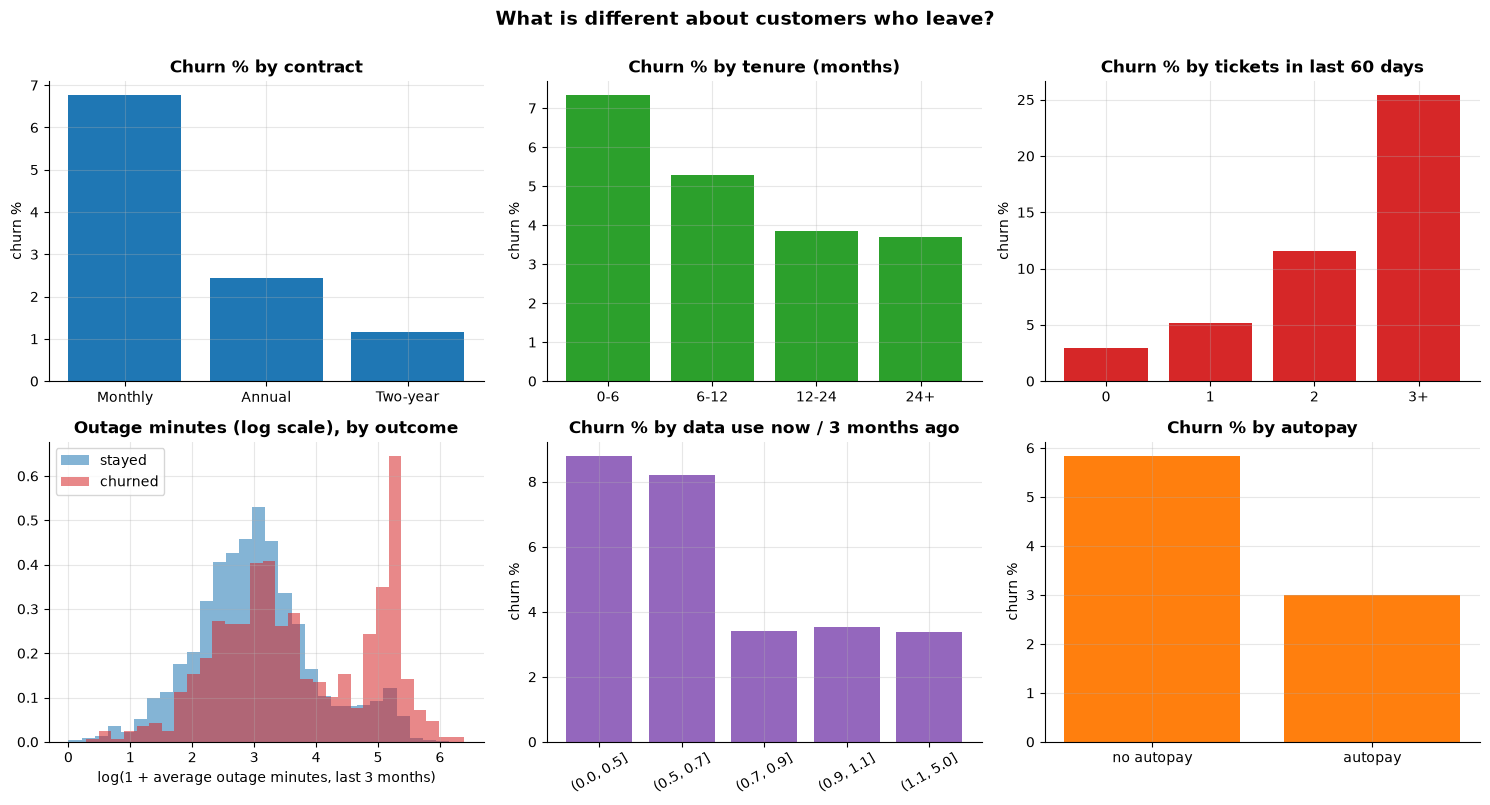

In [21]:
train_df["tenure_band"] = pd.cut(train_df["tenure_months"], [-1, 6, 12, 24, 100], labels=["0-6", "6-12", "12-24", "24+"])
train_df["tickets_60d_band"] = train_df["n_tickets_60d"].clip(upper=3).astype(int).astype(str).replace({"3": "3+"})

def rate(df, col):
    return df.groupby(col, observed=True)["label"].mean().mul(100)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

r = rate(train_df, "contract").reindex(["Monthly", "Annual", "Two-year"])
axes[0, 0].bar(r.index, r.values, color="#1f77b4")
axes[0, 0].set_title("Churn % by contract")

r = rate(train_df, "tenure_band")
axes[0, 1].bar(r.index.astype(str), r.values, color="#2ca02c")
axes[0, 1].set_title("Churn % by tenure (months)")

r = rate(train_df, "tickets_60d_band")
axes[0, 2].bar(r.index, r.values, color="#d62728")
axes[0, 2].set_title("Churn % by tickets in last 60 days")

for lab, color in [(0, "#1f77b4"), (1, "#d62728")]:
    axes[1, 0].hist(np.log1p(train_df.loc[train_df["label"] == lab, "avg_outage_3m"]), bins=30, alpha=0.55,
                    density=True, color=color, label="churned" if lab else "stayed")
axes[1, 0].set_title("Outage minutes (log scale), by outcome")
axes[1, 0].set_xlabel("log(1 + average outage minutes, last 3 months)")
axes[1, 0].legend()

r = train_df.groupby(pd.cut(train_df["gb_now_vs_3m_ago"], [0, 0.5, 0.7, 0.9, 1.1, 5]), observed=True)["label"].mean().mul(100)
axes[1, 1].bar([str(i) for i in r.index], r.values, color="#9467bd")
axes[1, 1].set_title("Churn % by data use now / 3 months ago")
axes[1, 1].tick_params(axis="x", rotation=30)

r = rate(train_df, "autopay")
axes[1, 2].bar(["no autopay", "autopay"], r.values, color="#ff7f0e")
axes[1, 2].set_title("Churn % by autopay")

for ax in axes.flat:
    if ax is not axes[1, 0]:
        ax.set_ylabel("churn %")
fig.suptitle("What is different about customers who leave?", fontsize=14, fontweight="bold", y=1.0)
plt.tight_layout()
plt.show()
savefig(fig, "02_eda_churn_drivers")

In [22]:
# The same insight as numbers: churn rate of the riskiest segment vs the safest one
overall = train_df["label"].mean() * 100
risky = train_df[(train_df["contract"] == "Monthly") & (train_df["autopay"] == 0) & (train_df["n_tickets_60d"] >= 1)]
safe = train_df[(train_df["contract"] != "Monthly") & (train_df["autopay"] == 1) & (train_df["n_tickets_60d"] == 0)]

print(f"overall churn rate                               : {overall:.1f}%")
print(f"monthly + no autopay + recent ticket ({len(risky):4d} rows): {risky['label'].mean() * 100:.1f}%")
print(f"long contract + autopay + no tickets ({len(safe):4d} rows): {safe['label'].mean() * 100:.1f}%")

overall churn rate                               : 4.4%
monthly + no autopay + recent ticket (1536 rows): 14.0%
long contract + autopay + no tickets (4481 rows): 1.1%


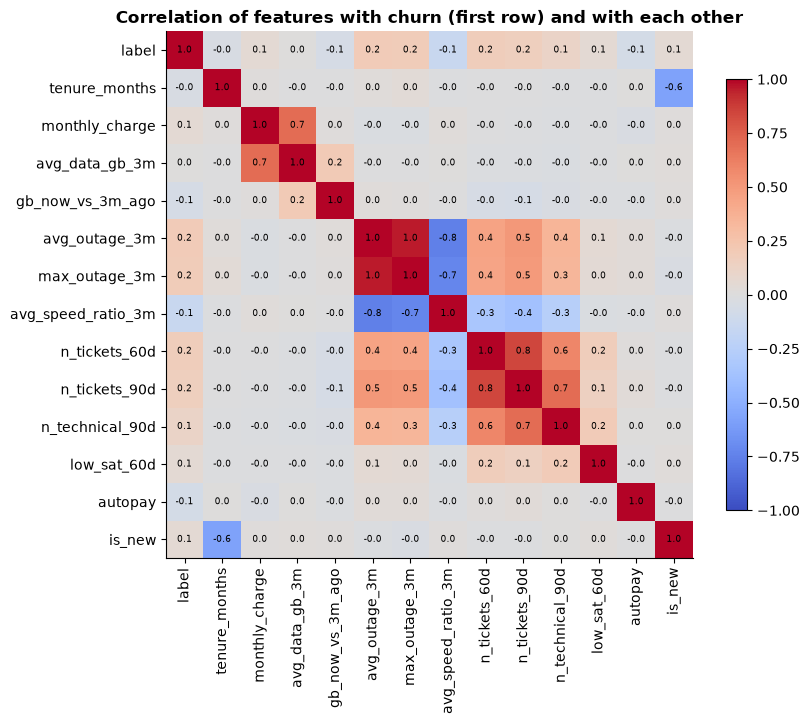

In [23]:
# Correlation heatmap of numeric features with the label (matplotlib only)
num = ["label", "tenure_months", "monthly_charge", "avg_data_gb_3m", "gb_now_vs_3m_ago", "avg_outage_3m", "max_outage_3m",
       "avg_speed_ratio_3m", "n_tickets_60d", "n_tickets_90d", "n_technical_90d", "low_sat_60d", "autopay", "is_new"]
corr = train_df[num].corr()

fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(num))); ax.set_xticklabels(num, rotation=90)
ax.set_yticks(range(len(num))); ax.set_yticklabels(num)
for i in range(len(num)):
    for j in range(len(num)):
        ax.text(j, i, f"{corr.iloc[i, j]:.1f}", ha="center", va="center", fontsize=6.5)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Correlation of features with churn (first row) and with each other")
plt.show()
savefig(fig, "03_correlation_heatmap")

**What the EDA tells us (write this in your report):**
- **Contract and autopay** matter a lot: monthly, non-autopay customers leave far more.
- **New customers** (first months) are the most fragile.
- **Outages, tickets and falling data use** all point to unhappy or disengaged customers.
- Some features are correlated with each other (tickets in 60 vs 90 days), which is fine for a regularized model.

**Say it in an interview:** "EDA on the training period only. I checked each hypothesis with a chart, and found a segment with several times the average churn, which is the signal the model will learn."

---
# 7. Prepare the model inputs (learn from train, apply to test)

Everything that is **learned from data** (medians for missing values, mean and standard deviation for scaling, dummy column names) is computed from the **training rows only** and then applied to the test rows (chapter 07: no leakage).

In [24]:
CAT_COLS = ["contract", "plan", "payment_method", "city"]
NUM_COLS = ["tenure_months", "is_new", "autopay", "monthly_charge", "age",
            "avg_data_gb_3m", "gb_now_vs_3m_ago", "avg_outage_3m", "max_outage_3m", "avg_speed_ratio_3m",
            "n_tickets_90d", "n_tickets_60d", "n_technical_90d", "avg_resolution_h", "low_sat_60d", "days_since_last_ticket"]
LOG_COLS = ["avg_data_gb_3m", "avg_outage_3m", "max_outage_3m", "avg_resolution_h"]      # right-skewed -> log1p

def fit_preprocessor(df):
    X = df[NUM_COLS].copy()
    p = {"medians": X.median()}
    X = X.fillna(p["medians"])
    X[LOG_COLS] = np.log1p(X[LOG_COLS])
    p["mean"], p["std"] = X.mean(), X.std().replace(0, 1)
    p["dummy_cols"] = pd.get_dummies(df[CAT_COLS], drop_first=True, dtype=float).columns
    return p

def transform(df, p):
    X = df[NUM_COLS].copy().fillna(p["medians"])
    X[LOG_COLS] = np.log1p(X[LOG_COLS])
    X = (X - p["mean"]) / p["std"]
    D = pd.get_dummies(df[CAT_COLS], dtype=float).reindex(columns=p["dummy_cols"], fill_value=0.0)
    return pd.concat([X, D], axis=1)

prep = fit_preprocessor(train_df)
X_train, y_train = transform(train_df, prep), train_df["label"].to_numpy()
X_test, y_test = transform(test_df, prep), test_df["label"].to_numpy()

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
assert list(X_train.columns) == list(X_test.columns) and not X_train.isna().any().any() and not X_test.isna().any().any()
X_train.describe().loc[["mean", "std"]].iloc[:, :6].round(2)

X_train: (19118, 28) | X_test: (5983, 28)


,tenure_months,is_new,autopay,monthly_charge,age,avg_data_gb_3m
mean,0.0,0.0,-0.0,0.0,0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0


---
# 8. The model: logistic regression from scratch (NumPy)

**Logistic regression** predicts a probability: `p = sigmoid(X @ w + b)` where `sigmoid(z) = 1 / (1 + e^-z)`.

We find `w` and `b` by **gradient descent** on the log loss (cross-entropy) with an L2 penalty:

```
loss      = - mean( y*log(p) + (1-y)*log(1-p) )  +  (l2 / 2n) * sum(w^2)
gradient  = X.T @ (p - y) / n  +  (l2 / n) * w          (for the weights)
          = mean(p - y)                                  (for the bias)
```

All of it is vectorized NumPy (`@`, broadcasting, no Python loop over rows).

In [25]:
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -30, 30)))

class LogisticRegressionScratch:
    def __init__(self, lr=0.5, n_iter=1500, l2=10.0):
        self.lr, self.n_iter, self.l2 = lr, n_iter, l2

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        n, d = X.shape
        self.w, self.b = np.zeros(d), 0.0
        self.history = []
        for i in range(self.n_iter):
            p = sigmoid(X @ self.w + self.b)
            error = p - y
            self.w -= self.lr * (X.T @ error / n + self.l2 * self.w / n)
            self.b -= self.lr * error.mean()
            if i % 25 == 0:
                eps = 1e-12
                loss = -np.mean(y * np.log(p + eps) + (1 - y) * np.log(1 - p + eps)) + self.l2 / (2 * n) * (self.w ** 2).sum()
                self.history.append((i, loss))
        return self

    def predict_proba(self, X):
        return sigmoid(np.asarray(X, dtype=float) @ self.w + self.b)

model = LogisticRegressionScratch().fit(X_train, y_train)
hist = np.array(model.history)
print(f"loss went from {hist[0, 1]:.4f} to {hist[-1, 1]:.4f} in {model.n_iter} steps")

loss went from 0.6932 to 0.1511 in 1500 steps


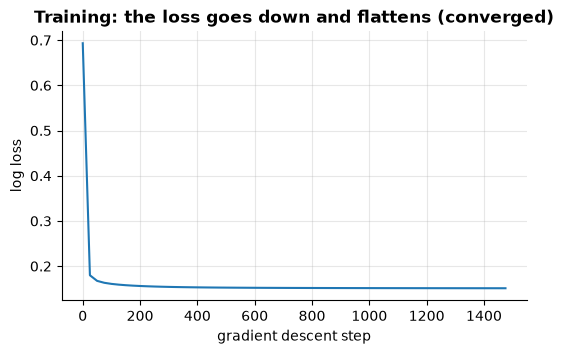

In [26]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(hist[:, 0], hist[:, 1], color="#1f77b4")
ax.set_xlabel("gradient descent step"); ax.set_ylabel("log loss")
ax.set_title("Training: the loss goes down and flattens (converged)")
plt.show()
savefig(fig, "04_loss_curve")

## 8.1 Metrics from scratch

| Metric | Meaning |
|---|---|
| **ROC AUC** | probability that a random churner gets a higher score than a random stayer (0.5 = random, 1.0 = perfect) |
| **Average precision (PR AUC)** | area under the precision-recall curve. Better than ROC AUC when churners are rare |
| **Precision@K** | of the top K customers we flag, how many really churn |
| **Lift@K** | precision@K divided by the overall churn rate ("K times better than random") |

Accuracy is useless here: predicting "nobody churns" is about 96% accurate and catches nobody.

In [27]:
def roc_auc(y, score):
    ranks = pd.Series(score).rank().to_numpy()                 # average ranks handle ties
    n1 = y.sum(); n0 = len(y) - n1
    return (ranks[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

def curves(y, score):
    order = np.argsort(-score)
    y_sorted = y[order]
    tp = np.cumsum(y_sorted); fp = np.cumsum(1 - y_sorted)
    tpr, fpr = tp / y.sum(), fp / (len(y) - y.sum())
    precision, recall = tp / (tp + fp), tp / y.sum()
    return fpr, tpr, precision, recall, y_sorted

def average_precision(y, score):
    *_, precision, recall, y_sorted = curves(y, score)
    return (precision * y_sorted).sum() / y.sum()               # mean of precision at every true churner

def precision_at_k(y, score, k):
    top = np.argsort(-score)[:k]
    return y[top].mean()

p_test = model.predict_proba(X_test)
base_rate = y_test.mean()

print(f"ROC AUC           : {roc_auc(y_test, p_test):.3f}")
print(f"Average precision : {average_precision(y_test, p_test):.3f}   (a random model would get {base_rate:.3f})")
for k in [100, 200, 400]:
    pk = precision_at_k(y_test, p_test, k)
    print(f"precision@{k:<3d}      : {pk:.3f}   lift {pk / base_rate:.1f}x")

ROC AUC           : 0.765
Average precision : 0.187   (a random model would get 0.036)
precision@100      : 0.300   lift 8.3x
precision@200      : 0.230   lift 6.4x
precision@400      : 0.175   lift 4.9x


## 8.2 Baselines: the model must beat simple rules

A model is only useful if it beats something simple that a manager could do without machine learning.

In [28]:
# Baseline 1: random scores. Baseline 2: a hand-made risk rule.
rng = np.random.default_rng(0)
rule_score = ((test_df["contract"] == "Monthly").astype(int) * 2
              + (test_df["autopay"] == 0).astype(int)
              + test_df["n_tickets_60d"].clip(upper=3)
              + test_df["is_new"]).to_numpy().astype(float) + rng.random(len(test_df)) * 0.01     # tiny noise breaks ties

results = pd.DataFrame({
    "random": [roc_auc(y_test, rng.random(len(y_test))), average_precision(y_test, rng.random(len(y_test))),
               precision_at_k(y_test, rng.random(len(y_test)), 200)],
    "hand-made rule": [roc_auc(y_test, rule_score), average_precision(y_test, rule_score), precision_at_k(y_test, rule_score, 200)],
    "logistic regression": [roc_auc(y_test, p_test), average_precision(y_test, p_test), precision_at_k(y_test, p_test, 200)],
}, index=["ROC AUC", "Average precision", "Precision@200"]).round(3)
results

,random,hand-made rule,logistic regression
ROC AUC,0.507,0.719,0.765
Average precision,0.032,0.125,0.187
Precision@200,0.025,0.180,0.230


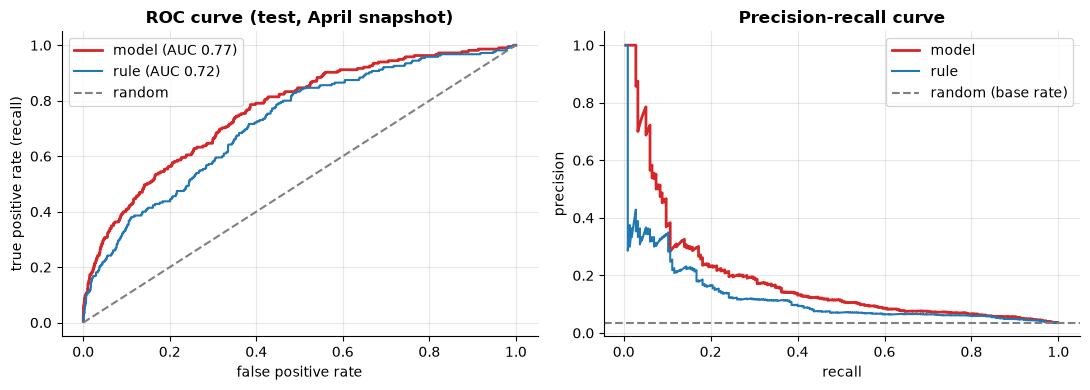

In [29]:
fpr, tpr, precision, recall, _ = curves(y_test, p_test)
fpr_r, tpr_r, precision_r, recall_r, _ = curves(y_test, rule_score)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(fpr, tpr, label=f"model (AUC {roc_auc(y_test, p_test):.2f})", color="#d62728", linewidth=2)
axes[0].plot(fpr_r, tpr_r, label=f"rule (AUC {roc_auc(y_test, rule_score):.2f})", color="#1f77b4")
axes[0].plot([0, 1], [0, 1], "--", color="gray", label="random")
axes[0].set_xlabel("false positive rate"); axes[0].set_ylabel("true positive rate (recall)")
axes[0].set_title("ROC curve (test, April snapshot)"); axes[0].legend()

axes[1].plot(recall, precision, color="#d62728", linewidth=2, label="model")
axes[1].plot(recall_r, precision_r, color="#1f77b4", label="rule")
axes[1].axhline(base_rate, linestyle="--", color="gray", label="random (base rate)")
axes[1].set_xlabel("recall"); axes[1].set_ylabel("precision")
axes[1].set_title("Precision-recall curve"); axes[1].legend()
plt.tight_layout()
plt.show()
savefig(fig, "05_roc_pr_curves")

---
# 9. Model checks

## 9.1 Lift chart: how much better than random is each risk group?

Sort customers by predicted risk, cut into 10 equal groups (deciles) and compare the real churn rate of each group.

In [30]:
check = pd.DataFrame({"p": p_test, "y": y_test})
check["decile"] = pd.qcut(check["p"].rank(method="first", ascending=False), 10, labels=range(1, 11))     # 1 = highest risk
lift = check.groupby("decile", observed=True).agg(customers=("y", "size"), churners=("y", "sum"),
                                                 churn_rate=("y", "mean"), avg_predicted=("p", "mean"))
lift["lift"] = lift["churn_rate"] / base_rate
lift["cum_churners_found_%"] = lift["churners"].cumsum() / lift["churners"].sum() * 100
lift.round(3)

,customers,churners,churn_rate,avg_predicted,lift,cum_churners_found_%
decile,,,,,,
1,599,84,0.140,0.172,3.902,39.070
2,598,34,0.057,0.071,1.582,54.884
3,598,21,0.035,0.048,0.977,64.651
4,598,28,0.047,0.036,1.303,77.674
5,599,12,0.020,0.028,0.557,83.256
6,598,16,0.027,0.021,0.745,90.698
7,598,7,0.012,0.016,0.326,93.953
8,598,5,0.008,0.011,0.233,96.279
9,598,4,0.007,0.008,0.186,98.140


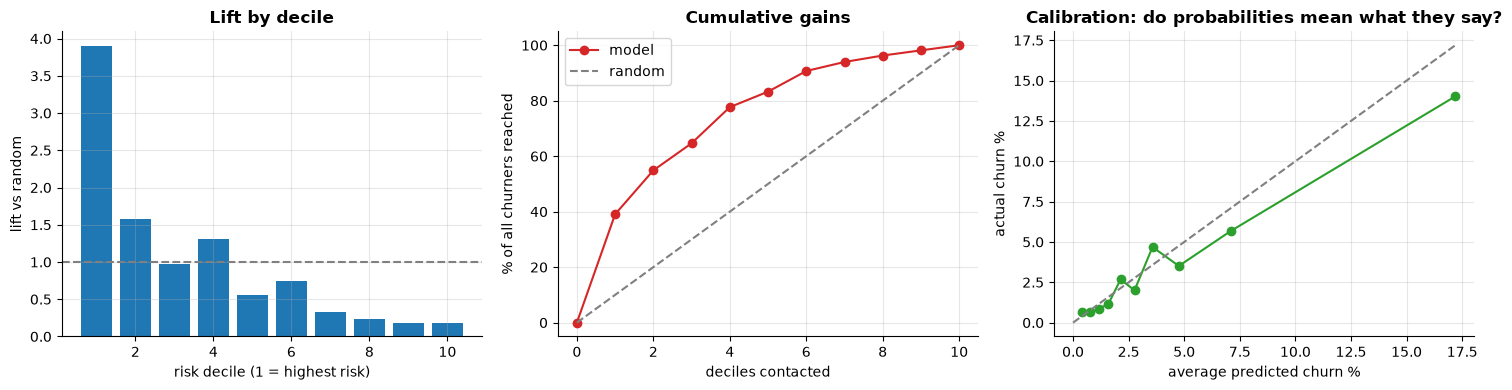

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].bar(lift.index.astype(int), lift["lift"], color="#1f77b4")
axes[0].axhline(1, linestyle="--", color="gray")
axes[0].set_xlabel("risk decile (1 = highest risk)"); axes[0].set_ylabel("lift vs random")
axes[0].set_title("Lift by decile")

axes[1].plot(np.arange(0, 11), [0] + lift["cum_churners_found_%"].tolist(), marker="o", color="#d62728", label="model")
axes[1].plot([0, 10], [0, 100], "--", color="gray", label="random")
axes[1].set_xlabel("deciles contacted"); axes[1].set_ylabel("% of all churners reached")
axes[1].set_title("Cumulative gains"); axes[1].legend()

axes[2].plot(lift["avg_predicted"] * 100, lift["churn_rate"] * 100, marker="o", color="#2ca02c")
mx = max(lift["avg_predicted"].max(), lift["churn_rate"].max()) * 100
axes[2].plot([0, mx], [0, mx], "--", color="gray")
axes[2].set_xlabel("average predicted churn %"); axes[2].set_ylabel("actual churn %")
axes[2].set_title("Calibration: do probabilities mean what they say?")

plt.tight_layout()
plt.show()
savefig(fig, "06_lift_gains_calibration")

- **Lift:** the top deciles churn many times more than average.
- **Gains:** contacting the top 20% of customers reaches a large share of all churners.
- **Calibration:** the points near the diagonal mean a predicted 10% really behaves like 10%. That matters for the profit rule in section 10, which uses the probabilities themselves.

## 9.2 What did the model learn? (coefficients)

Features are standardized, so the sizes of the weights can be compared. `exp(weight)` is the **odds ratio** for +1 standard deviation (or for the category being present).

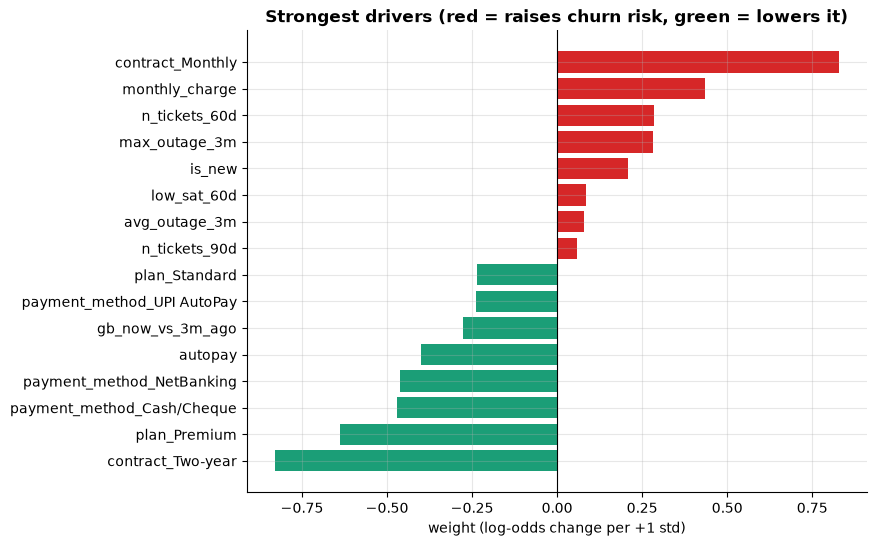

,weight,odds_ratio
contract_Monthly,0.83,2.29
monthly_charge,0.44,1.55
n_tickets_60d,0.29,1.33
max_outage_3m,0.28,1.33
is_new,0.21,1.23
avg_outage_3m,0.08,1.08
low_sat_60d,0.08,1.09
n_tickets_90d,0.06,1.06
payment_method_UPI AutoPay,-0.24,0.79
plan_Standard,-0.24,0.79


In [32]:
coefs = pd.Series(model.w, index=X_train.columns).sort_values()
top = pd.concat([coefs.head(8), coefs.tail(8)])

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, top.values, color=np.where(top.values > 0, "#d62728", "#1b9e77"))
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Strongest drivers (red = raises churn risk, green = lowers it)")
ax.set_xlabel("weight (log-odds change per +1 std)")
plt.show()
savefig(fig, "07_coefficients")

pd.DataFrame({"weight": top, "odds_ratio": np.exp(top)}).round(2).sort_values("weight", ascending=False)

In [33]:
# Does the model work equally well for every customer group? (AUC per group)
seg = test_df.assign(p=p_test)
rows = []
for col in ["contract", "plan", "city"]:
    for value, g in seg.groupby(col):
        if g["label"].sum() >= 5:
            rows.append({"group": f"{col} = {value}", "customers": len(g), "churners": int(g["label"].sum()),
                         "auc": round(roc_auc(g["label"].to_numpy(), g["p"].to_numpy()), 3)})
pd.DataFrame(rows)

,group,customers,churners,auc
0,contract = Annual,2085,40,0.744
1,contract = Monthly,2805,155,0.712
2,contract = Two-year,1093,20,0.760
3,plan = Basic,2819,95,0.756
4,plan = Premium,846,36,0.786
5,plan = Standard,2318,84,0.769
6,city = Bhopal,1271,42,0.765
7,city = Indore,1491,45,0.774
8,city = Jaipur,899,39,0.751
9,city = Lucknow,595,23,0.790


In [34]:
# Validate our from-scratch model against scikit-learn (optional: pip install scikit-learn)
try:
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import roc_auc_score

    sk = LogisticRegression(C=1.0 / 10.0, max_iter=2000).fit(X_train, y_train)      # C = 1 / l2 strength (same as our l2=10 on the summed loss)
    sk_p = sk.predict_proba(X_test)[:, 1]
    print(f"scikit-learn AUC: {roc_auc_score(y_test, sk_p):.4f} | our AUC: {roc_auc(y_test, p_test):.4f}")
    print("correlation of the two sets of probabilities:", round(np.corrcoef(sk_p, p_test)[0, 1], 4))
except ImportError:
    print("scikit-learn is not installed. This check is optional: pip install scikit-learn")

scikit-learn is not installed. This check is optional: pip install scikit-learn


**Say it in an interview:** "I wrote logistic regression with NumPy to understand it, checked ROC AUC and average precision against a random baseline and a business rule, looked at lift and calibration by decile, and validated my implementation against scikit-learn. Accuracy would be misleading because only about 4% churn."

---
# 10. From predictions to a business decision

A model is not the goal. **Money** is. Assumptions for the retention campaign (change them and re-run, this is a good interview discussion):

| Assumption | Value |
|---|---|
| Cost of one retention call plus offer | **Rs. 250** |
| Probability that a contacted churner is saved | **35%** |
| Value of a saved customer | **12 months of their bill** |

**Decision rule:** contact a customer when the *expected value* is positive:

```
expected value = churn probability x save rate x (12 x monthly bill)  -  cost of contact
```

In [35]:
COST, SAVE_RATE, MONTHS_VALUE = 250, 0.35, 12

value_if_saved = (MONTHS_VALUE * test_df["monthly_charge"]).to_numpy()
expected_value = p_test * SAVE_RATE * value_if_saved - COST

contact = expected_value > 0                         # decision uses ONLY predicted probabilities, not the real labels
print(f"customers to contact: {contact.sum()} of {len(contact)} ({contact.mean() * 100:.1f}%)")

customers to contact: 748 of 5983 (12.5%)


In [36]:
def realised_profit(contact_mask, y, value_if_saved):
    """What really happened: we only gain from contacted customers who truly were going to leave."""
    saved_value = SAVE_RATE * (y * value_if_saved)[contact_mask].sum()
    return saved_value - COST * contact_mask.sum()

strategies = {
    "do nothing": np.zeros(len(y_test), dtype=bool),
    "contact everyone": np.ones(len(y_test), dtype=bool),
    "contact a random 5%": np.random.default_rng(1).random(len(y_test)) < 0.05,
    "hand-made rule (top 5%)": rule_score >= np.quantile(rule_score, 0.95),
    "MODEL: expected value > 0": contact,
}
profit = pd.Series({name: realised_profit(m, y_test, value_if_saved) for name, m in strategies.items()})
summary = pd.DataFrame({"customers_contacted": {n: int(m.sum()) for n, m in strategies.items()},
                        "profit_rs": profit.round(0)})
summary

,customers_contacted,profit_rs
do nothing,0,0.0
contact everyone,5983,-847564.0
contact a random 5%,298,-53689.0
hand-made rule (top 5%),300,76599.0
MODEL: expected value > 0,748,124308.0


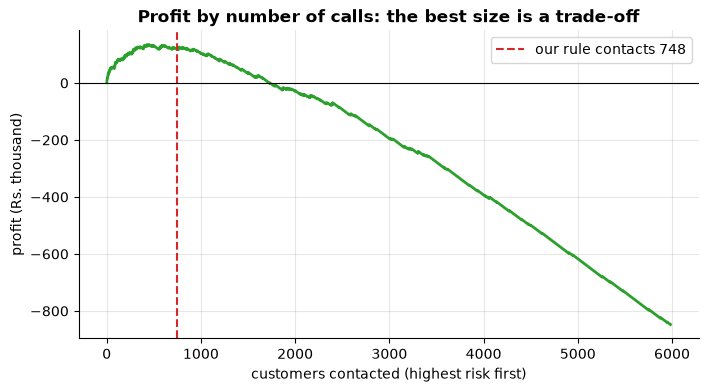

best K on the test data: 449 customers, profit Rs. 134,815 (for reference only, we do not choose K on test data)


In [37]:
# Profit curve: what if we contact the top K customers by risk?
order = np.argsort(-p_test)
gain = np.cumsum(SAVE_RATE * (y_test * value_if_saved)[order])
spent = COST * np.arange(1, len(order) + 1)
curve = gain - spent
best_k = int(curve.argmax()) + 1

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(np.arange(1, len(curve) + 1), curve / 1000, color="#2ca02c", linewidth=2)
ax.axvline(contact.sum(), linestyle="--", color="#d62728", label=f"our rule contacts {contact.sum()}")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("customers contacted (highest risk first)")
ax.set_ylabel("profit (Rs. thousand)")
ax.set_title("Profit by number of calls: the best size is a trade-off")
ax.legend()
plt.show()
savefig(fig, "08_profit_curve")

print(f"best K on the test data: {best_k} customers, profit Rs. {curve.max():,.0f} (for reference only, we do not choose K on test data)")

Strategies compared:
- **Do nothing** earns nothing.
- **Contact everyone** costs more than it saves (most people were not going to leave).
- **A hand-made rule** helps a little.
- **The model's rule** contacts a small group with the highest expected value and earns the most.

The decision rule was set from **probabilities only**, never from the test labels, so this is an honest estimate of what would happen next month.

**Say it in an interview:** "I turned probabilities into a decision using expected value with explicit cost and save-rate assumptions, compared it with 'do nothing', 'call everyone' and a rule, and measured realised profit on the future snapshot."

---
# 11. Produce the deliverable: this month's call list

The same functions give today's call list: build the features for the **latest** date and score the customers.

In [38]:
call_list = test_df.assign(churn_probability=p_test, expected_value_rs=expected_value.round(0))
call_list = (call_list[contact]
             .sort_values("expected_value_rs", ascending=False)
             .reset_index()[["customer_id", "city", "plan", "contract", "monthly_charge", "n_tickets_60d",
                             "avg_outage_3m", "churn_probability", "expected_value_rs"]])
call_list["churn_probability"] = call_list["churn_probability"].round(3)
call_list["avg_outage_3m"] = call_list["avg_outage_3m"].round(0)
call_list.head(10)

,customer_id,city,plan,contract,monthly_charge,n_tickets_60d,avg_outage_3m,churn_probability,expected_value_rs
0,C00596,Bhopal,Premium,Monthly,1299.0,4.0,193.0,0.780,4008.0
1,C05177,Bhopal,Premium,Monthly,1299.0,1.0,210.0,0.506,2509.0
2,C03129,Jaipur,Premium,Monthly,1299.0,3.0,96.0,0.462,2273.0
3,C05672,Lucknow,Standard,Monthly,799.0,5.0,229.0,0.750,2266.0
4,C07281,Bhopal,Premium,Monthly,1299.0,1.0,219.0,0.432,2109.0
5,C06713,Bhopal,Premium,Monthly,1299.0,0.0,127.0,0.420,2042.0
6,C07387,Indore,Premium,Monthly,1299.0,2.0,210.0,0.394,1899.0
7,C07529,Pune,Standard,Monthly,799.0,4.0,388.0,0.633,1876.0
8,C00171,Lucknow,Premium,Monthly,1234.0,0.0,199.0,0.409,1870.0
9,C00863,Indore,Premium,Monthly,1299.0,0.0,191.0,0.367,1752.0


In [39]:
# Save everything for your GitHub repo: clean data, features, call list and the model weights
c.to_csv(DATA / "customers_clean.csv", index=False)
train_df.drop(columns=["tenure_band", "tickets_60d_band"]).to_csv(DATA / "features_train.csv")
test_df.to_csv(DATA / "features_test.csv")
call_list.to_csv(DATA / "call_list_top.csv", index=False)

model_card = {
    "model": "logistic regression (NumPy, L2=10, lr=0.5, 1500 steps)",
    "train_snapshots": TRAIN_SNAPSHOTS, "test_snapshot": TEST_SNAPSHOT,
    "test_roc_auc": round(float(roc_auc(y_test, p_test)), 4),
    "test_average_precision": round(float(average_precision(y_test, p_test)), 4),
    "weights": {k: round(float(v), 4) for k, v in zip(X_train.columns, model.w)}, "bias": round(float(model.b), 4),
}
(DATA / "model_card.json").write_text(json.dumps(model_card, indent=2))
print(sorted(p.name for p in DATA.glob("*") if "raw" not in p.name))

['call_list_top.csv', 'customers_clean.csv', 'features_test.csv', 'features_train.csv', 'model_card.json']


---
# 12. Summary, resume bullets, interview questions

In [40]:
auc = roc_auc(y_test, p_test); ap = average_precision(y_test, p_test)
top_decile_lift = lift.loc[1, "lift"]
model_profit = profit["MODEL: expected value > 0"]
print("RESULTS (future snapshot, never seen in training)")
print(f"  ROC AUC {auc:.3f} | average precision {ap:.3f} (random {base_rate:.3f}) | top-decile lift {top_decile_lift:.1f}x")
print(f"  model rule contacts {contact.sum()} customers and earns Rs. {model_profit:,.0f}; calling everyone earns Rs. {profit['contact everyone']:,.0f}")

print("\nRESUME BULLETS (use your own numbers from above)")
print(f"- Built a 30-day churn prediction pipeline on 8,000 broadband customers: cleaned 3 messy raw tables, engineered usage, support-ticket and contract features with pandas, and used snapshot-based time splits to avoid leakage.")
print(f"- Implemented logistic regression from scratch in NumPy (gradient descent, L2) and evaluation metrics (ROC AUC {auc:.2f}, top-decile lift {top_decile_lift:.1f}x), validated against scikit-learn.")
print(f"- Converted predictions into an expected-value retention policy that beat 'call everyone' by Rs. {(model_profit - profit['contact everyone']):,.0f} on the held-out month.")

RESULTS (future snapshot, never seen in training)
  ROC AUC 0.765 | average precision 0.187 (random 0.036) | top-decile lift 3.9x
  model rule contacts 748 customers and earns Rs. 124,308; calling everyone earns Rs. -847,564

RESUME BULLETS (use your own numbers from above)
- Built a 30-day churn prediction pipeline on 8,000 broadband customers: cleaned 3 messy raw tables, engineered usage, support-ticket and contract features with pandas, and used snapshot-based time splits to avoid leakage.
- Implemented logistic regression from scratch in NumPy (gradient descent, L2) and evaluation metrics (ROC AUC 0.77, top-decile lift 3.9x), validated against scikit-learn.
- Converted predictions into an expected-value retention policy that beat 'call everyone' by Rs. 971,872 on the held-out month.


## Likely interview questions about this project

**1. Why snapshots and a time-based split instead of a random split?**
A random split would let the model see the future of the same customers, which inflates the score. In production we predict the next month from past data, so the test must be a later period.

**2. How did you prevent data leakage?**
Features only use rows dated on or before the snapshot, labels only the next 30 days, preprocessing statistics (medians, scaling) are learned from training rows only, and I added `assert` checks for the time rules.

**3. Why is accuracy a bad metric here?**
About 4% churn: a model that says "nobody leaves" is 96% accurate and useless. ROC AUC, average precision, precision@K and lift fit rare events.

**4. How do you choose the threshold?**
From the business: expected value = probability x save rate x customer value - cost. The threshold is where it is zero, and it changes when costs or capacity change.

**5. Why logistic regression first?**
It is fast, interpretable (odds ratios), well calibrated, and a strong baseline. A tree-based model can come next, but it must beat this baseline and be explainable to the retention team.

**6. How do you know the probabilities are trustworthy?**
A calibration plot by decile (predicted vs actual). If it is off, recalibrate (Platt scaling or isotonic regression).

**7. What if churn behaviour changes over time (drift)?**
Monitor the score distribution and churn rate monthly, retrain on a rolling window, and re-check calibration.

**8. How did you handle missing values?**
Fake or impossible values became NaN, counts of events became 0 (no tickets = zero tickets), and other columns were filled with the median learned from training data, with the "no survey answer" case left as is.

**9. What would you improve with more time?**
Gradient boosting for non-linear effects, survival analysis (time to churn), an A/B test of the retention offer to measure the real save rate, and monitoring in production.

**10. How would you put it in production?**
A monthly job: build features for today's snapshot, score customers, write the call list. Serve the model with FastAPI, show it in a Streamlit dashboard, and track outcomes to measure the real campaign profit.

## Extension ideas

1. Replace the model by `sklearn.ensemble.GradientBoostingClassifier` and compare lift and calibration.
2. Add features: number of plan changes, payment failures, speed complaints, days since the last bill dispute.
3. Run the **save-rate sensitivity analysis**: how does profit change if the save rate is 15% instead of 35%?
4. Build a **Streamlit** dashboard (your folder `21_streamlit`) that shows the call list and lets the user change the cost assumptions.
5. Serve the scoring as a **FastAPI** endpoint (your folder `22_fast_api`).

## Revision sheet: functions you practised

| Library | Functions and ideas |
|---|---|
| **pandas** | `read_csv(dtype, parse_dates)`, `drop_duplicates`, `str.replace/strip/title`, `to_numeric`, `to_datetime(format="ISO8601" / "mixed")`, `merge(validate=)`, `join`, `groupby().agg(named)`, `pivot`, `cut`, `qcut`, `get_dummies`, `reindex`, `clip`, `where`, `fillna`, `rank`, `Period` |
| **NumPy** | `@`, broadcasting, `clip`, `exp`, `log`, `argsort`, `cumsum`, `quantile`, boolean masks, `np.add.at` (in the simulator), `random.default_rng` |
| **Matplotlib** | `subplots`, `bar`, `barh`, `hist`, `plot`, `hlines`, `imshow` + `text` (heatmap), `axhline`, `savefig` |
| **ML ideas** | snapshots, leakage guards, standardization (fit on train), logistic regression, ROC/PR, lift, calibration, expected-value decisions |